# Regional Pacific sea-level projections

Projection counterpart of the [historical regional sea-level notebook](../../../historical/Regional/sea_level/regional_indicators.ipynb). It maps how much and how fast sea level is projected to rise across the tropical and subtropical Pacific using the **IPCC AR6 sea-level projections** (Fox-Kemper et al., 2021; Garner et al., 2021), product `ar6-regional_novlm-confidence` — total sea-level change **without vertical land motion**, i.e. the ocean (absolute) signal that satellite altimetry measures:

1. global context: the projected 2020–2100 trend worldwide, with the Pacific window analysed below;
2. absolute sea-level change (cm, relative to 1995–2014) by 2050 and 2100 for SSP1-2.6, SSP2-4.5, SSP3-7.0 and SSP5-8.5;
3. rates of sea-level rise (mm/yr) around 2050 and 2100, and the mean trend over 2020–2100;
4. the area-weighted regional mean and its likely range to 2150;
5. the mean change in every Pacific EEZ and ocean region.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

In [2]:
from pathlib import Path
import sys, warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

warnings.filterwarnings('ignore', category=RuntimeWarning)

root_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
repo_root = next((p for p in root_candidates if (p / 'functions' / 'sea_level_projections.py').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Could not locate the CIndRA repository root (functions/sea_level_projections.py).')
sys.path.insert(0, str(repo_root / 'functions'))

import projections_regional as reg
from sea_level import save_dict_json
from sea_level_projections import (
    colour_limits, domain_mean, fill_coast, likely_range_table, linear_trend, load_ar6_global_median, load_ar6_pacific,
    plot_domain_mean_series, plot_global_context_grid, plot_projection_grid, region_table, ssp_label,
)
from sst import PacificSST, plot_pacific_sst_panels

## 1. Configuration

The map window matches the historical regional sea-level and SST analyses (125°E–115°W, 35°S–35°N). Every figure shows the four SSP scenarios on a shared colour scale. Set `include_vlm = True` to switch to the product with vertical land motion (`ar6-regional-confidence.zip`), which is relative sea level as a tide gauge would record it.

In [3]:
data_dir = repo_root / 'data'
raw_dir = data_dir / 'projections' / 'sea_level'          # raw AR6 global files (downloaded if missing)
eez_file = data_dir / 'regional' / 'Pacific_EEZs' / 'Pacific_EEZs.shp'
fig_dir = repo_root / 'outputs' / 'figures' / 'regional_pacific'
tab_dir = repo_root / 'outputs' / 'tables' / 'regional_pacific'
for directory in (fig_dir, tab_dir):
    directory.mkdir(parents=True, exist_ok=True)

pacific_extent = (125, 245, -35, 35)
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
horizons = [2050, 2100]
trend_period = (2020, 2100)
confidence = 'medium'
include_vlm = False
force_download = False
seq_cmap = 'afmhot_r'   # sequential: every projected change is positive; the scale starts at the minimum value

product_tag = 'ar6_vlm' if include_vlm else 'ar6_novlm'
cache_file = data_dir / 'projections' / 'regional' / f'sl_{product_tag}_{confidence}_pacific.nc'
global_cache_file = data_dir / 'projections' / 'regional' / f'sl_{product_tag}_{confidence}_global_median.nc'

## 2. AR6 sea-level projections

The [Zenodo record 6382554](https://zenodo.org/records/6382554) distributes the AR6 projections as 8–9 GB archives. `download_ar6_sea_level_projections` (in `functions/data_downloaders.py`) reads the archive remotely with HTTP range requests and extracts only the `total_<ssp>_medium_confidence_values.nc` and `..._rates.nc` files (~110 MB per scenario) into `data/projections/sea_level/`; files already present are reused.

Each file contains quantiles of sea-level change (mm, relative to 1995–2014) or of its rate (mm/yr) for every decade 2020–2150 at a global 1° grid and at the PSMSL tide gauges. The window is subset, land cells are masked with Natural Earth, change is converted to cm, and the result is cached in `data/projections/regional/`. Medium-confidence projections exclude the low-likelihood, high-impact ice-sheet processes.

In [4]:
sl = load_ar6_pacific(raw_dir, cache_file, ssp_scenarios, pacific_extent, confidence=confidence,
                      vlm=include_vlm, force_download=force_download)
eez = gpd.read_file(eez_file).to_crs(4326)
pacific = PacificSST(data_raw=sl, data=sl, eez=eez, extent=pacific_extent)
change = sl['change']   # cm, (scenario, quantile, year, lat, lon)
rate = sl['rate']       # mm/yr
print(f"{sl.attrs['product']}; vertical land motion {sl.attrs['vertical_land_motion']}")
print(f"{int(sl.ocean.sum())} ocean cells (1°) in the window; years {int(sl.year[0])}–{int(sl.year[-1])}")

regional_novlm total, medium confidence; vertical land motion excluded
7944 ocean cells (1°) in the window; years 2020–2150


## 3. Global context

Median trend of sea-level change over 2020–2100 on the global 1° grid (mm/yr), with the Pacific window analysed in the rest of the notebook outlined. Rise is not uniform: it is close to or above the global mean in the tropical Pacific and much lower near Greenland and Antarctica, where the loss of ice mass reduces the gravitational pull on the ocean. Same colour scale as the Pacific trend maps (from the minimum to the maximum trend in the window; lower values elsewhere, e.g. near the ice sheets, take the lowest colour); the four scenarios share one figure.

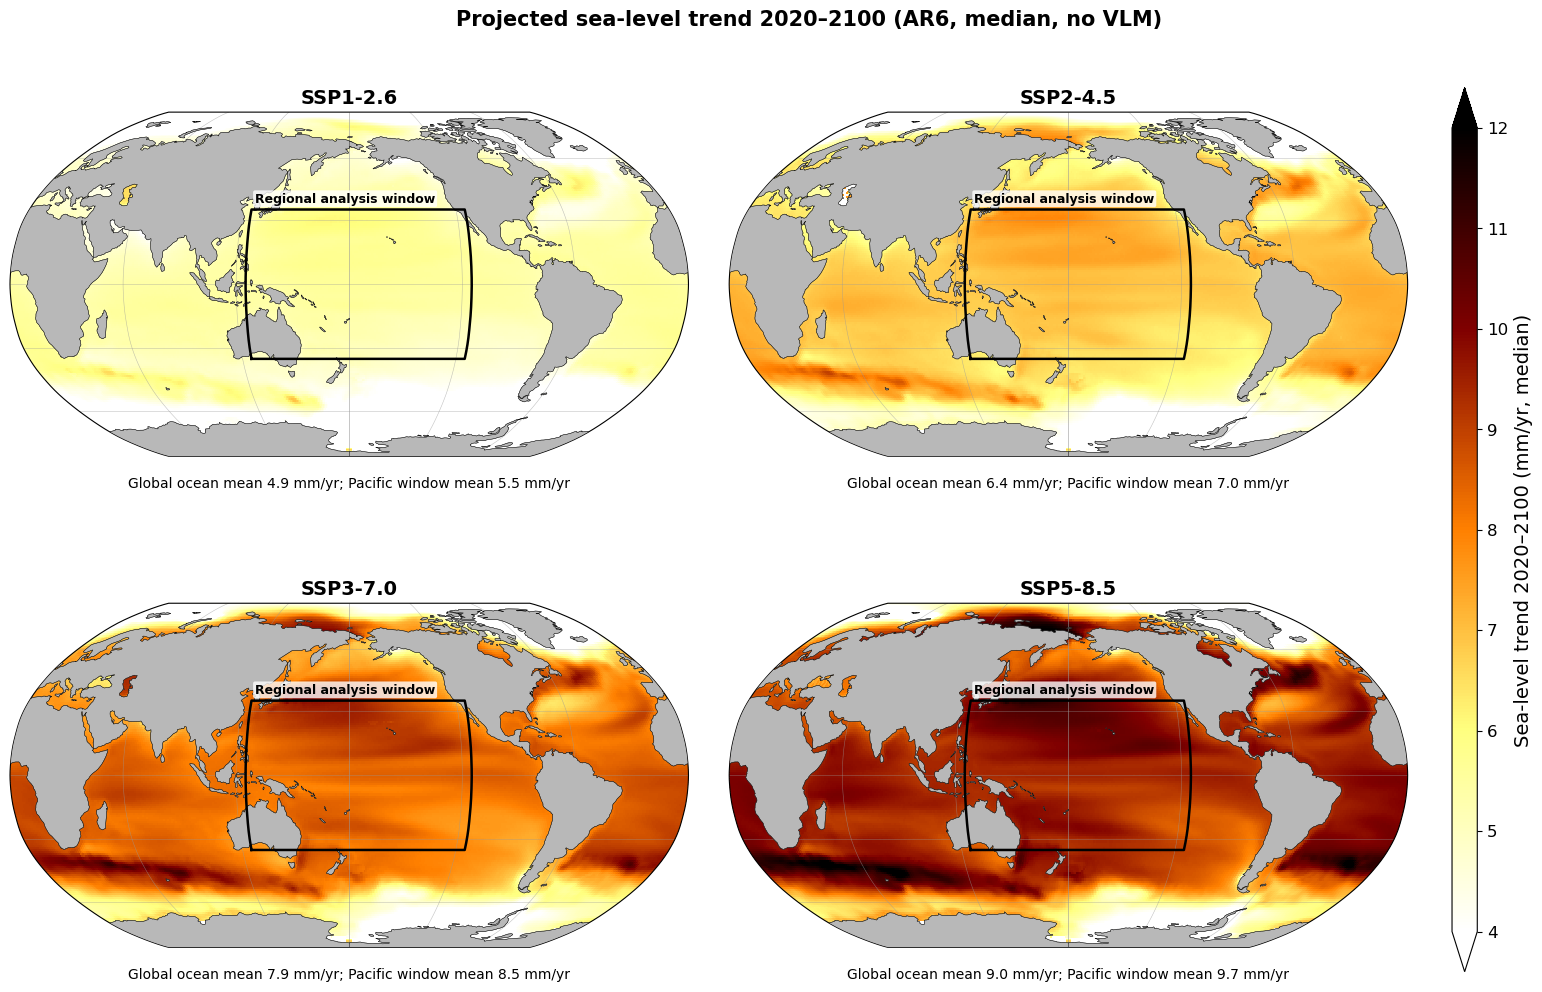

In [5]:
glob = load_ar6_global_median(raw_dir, global_cache_file, ssp_scenarios, confidence=confidence,
                              vlm=include_vlm, force_download=force_download)
global_trend = 10 * linear_trend(glob['change'], *trend_period)          # cm/yr -> mm/yr
window_trend = global_trend.sel(lat=slice(pacific_extent[2], pacific_extent[3]),
                                lon=slice(pacific_extent[0], pacific_extent[1]))
trend_vmin, trend_vmax, trend_levels = colour_limits(window_trend, 1)   # shared with the Pacific trend maps
fig = plot_global_context_grid(
    {ssp_label(s): global_trend.sel(scenario=s) for s in ssp_scenarios}, pacific_extent,
    f'Projected sea-level trend {trend_period[0]}–{trend_period[1]} (AR6, median, no VLM)',
    f'Sea-level trend {trend_period[0]}–{trend_period[1]} (mm/yr, median)', cmap=seq_cmap, vmin=trend_vmin, vmax=trend_vmax,
    annotations={ssp_label(s): f'Global ocean mean {float(domain_mean(global_trend.sel(scenario=s))):.1f} mm/yr; '
                               f'Pacific window mean {float(domain_mean(window_trend.sel(scenario=s))):.1f} mm/yr'
                 for s in ssp_scenarios},
    filename=fig_dir / f'PRJ_SL_trend_global_context_{product_tag}.png',
)
plt.show()

## 4. Absolute sea-level change

Median projected change relative to 1995–2014. One figure per horizon; the four scenarios share the colour scale and contours, and each panel gives the area-weighted ocean mean and its likely (17–83 %) range. Because the projected change is positive everywhere, the colour scale is sequential and runs from the minimum to the maximum value of each horizon, to bring out the spatial differences.

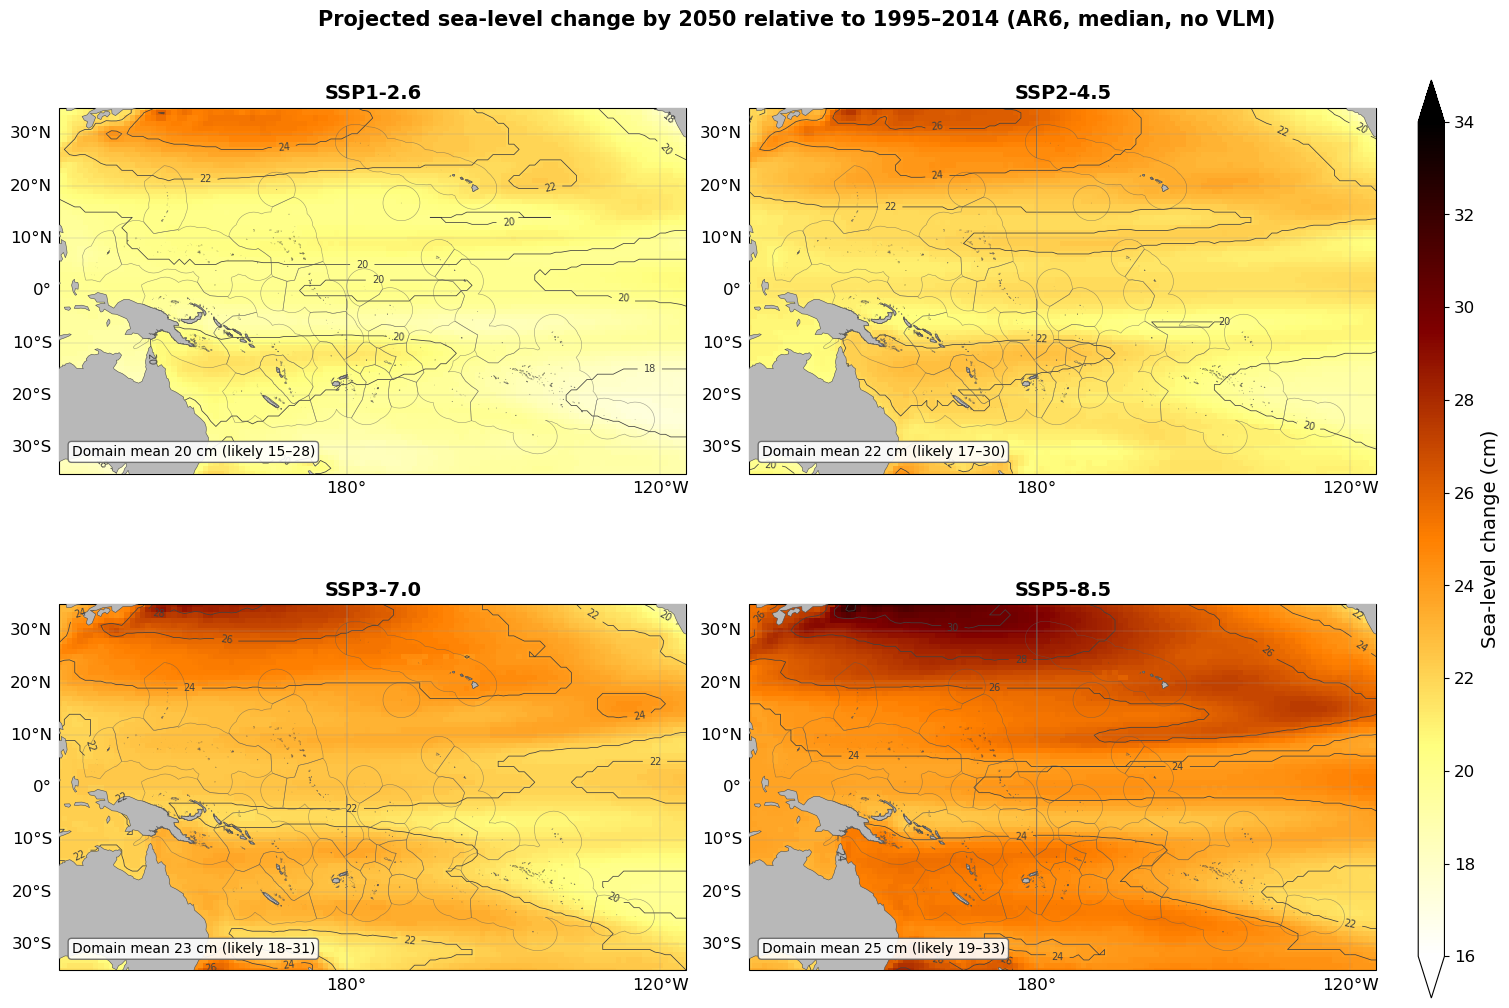

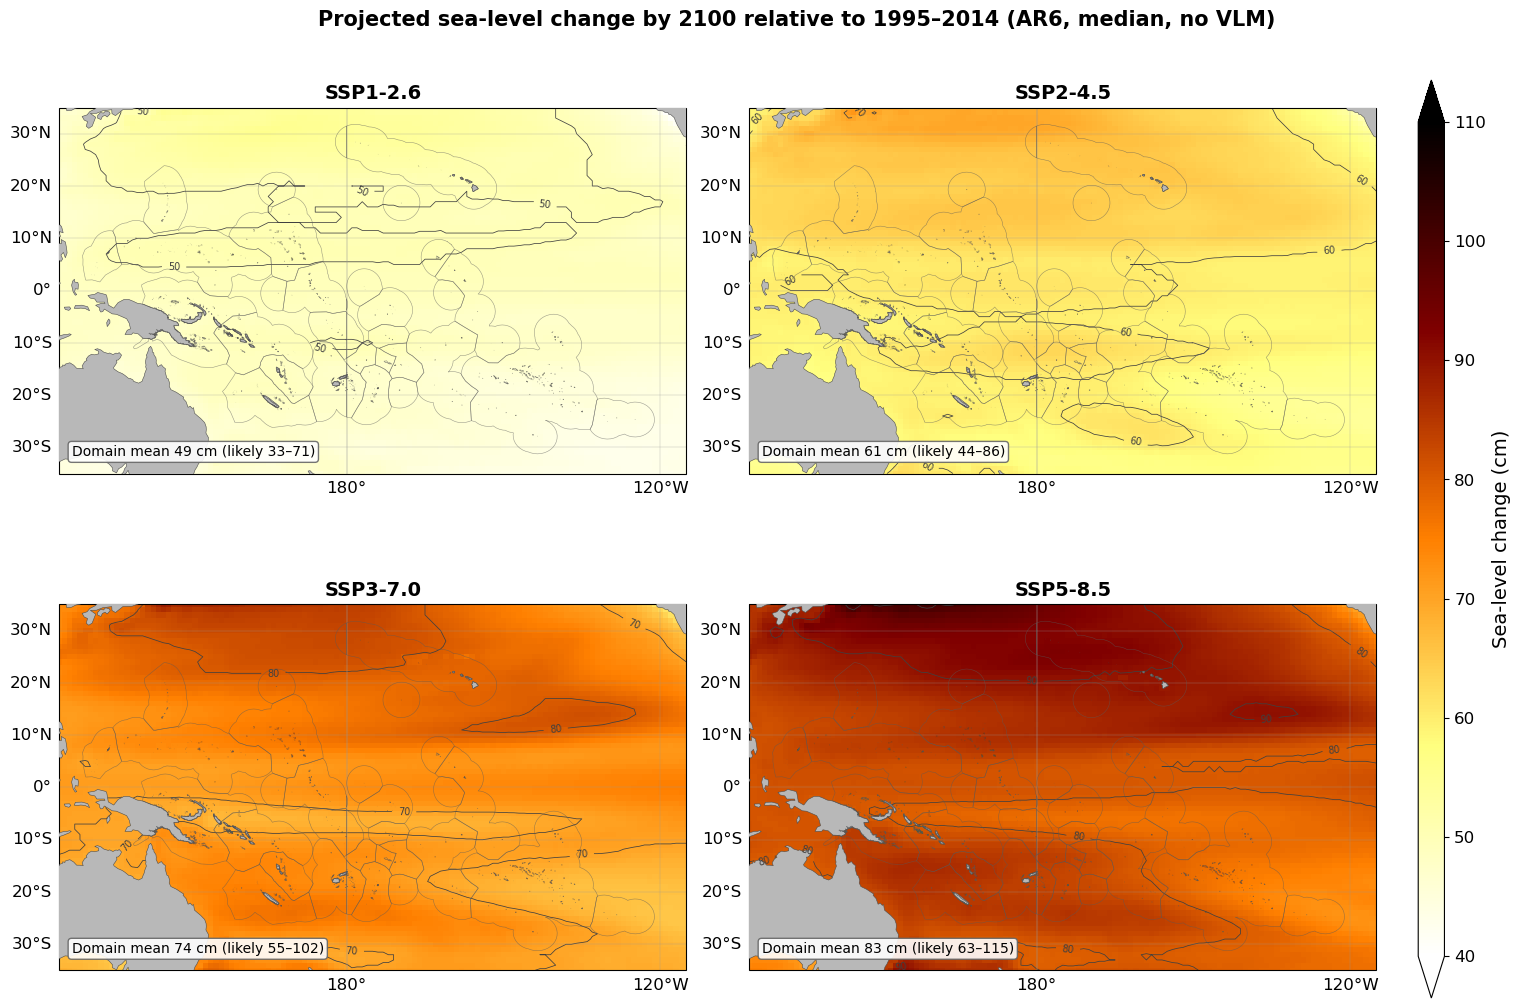

In [6]:
change_mean = domain_mean(change)
change_limits = {year: colour_limits(change.sel(quantile=0.5, year=year), 2 if year <= 2060 else 10) for year in horizons}
for year in horizons:
    vmin, vmax, levels = change_limits[year]
    m = change_mean.sel(year=year)
    fig = plot_projection_grid(
        {ssp_label(s): change.sel(scenario=s, quantile=0.5, year=year) for s in ssp_scenarios}, pacific,
        f'Projected sea-level change by {year} relative to 1995–2014 (AR6, median, no VLM)', 'Sea-level change (cm)',
        cmap=seq_cmap, vmin=vmin, vmax=vmax, contour_levels=levels,
        annotations={ssp_label(s): f"Domain mean {float(m.sel(scenario=s, quantile=0.5)):.0f} cm "
                                   f"(likely {float(m.sel(scenario=s, quantile=0.17)):.0f}–{float(m.sel(scenario=s, quantile=0.83)):.0f})"
                     for s in ssp_scenarios},
        filename=fig_dir / f'PRJ_SL_change_{year}_{product_tag}_pacific.png',
    )
    plt.show()

## 5. Rate of sea-level rise

### AR6 rates around 2050 and 2100

AR6 provides the rate of change (mm/yr) for each decade, close to the centred decadal rate around the labelled year. Rates keep increasing through the century under the higher scenarios, while under SSP1-2.6 they stabilise. All panels share one sequential colour scale from the minimum to the maximum rate.

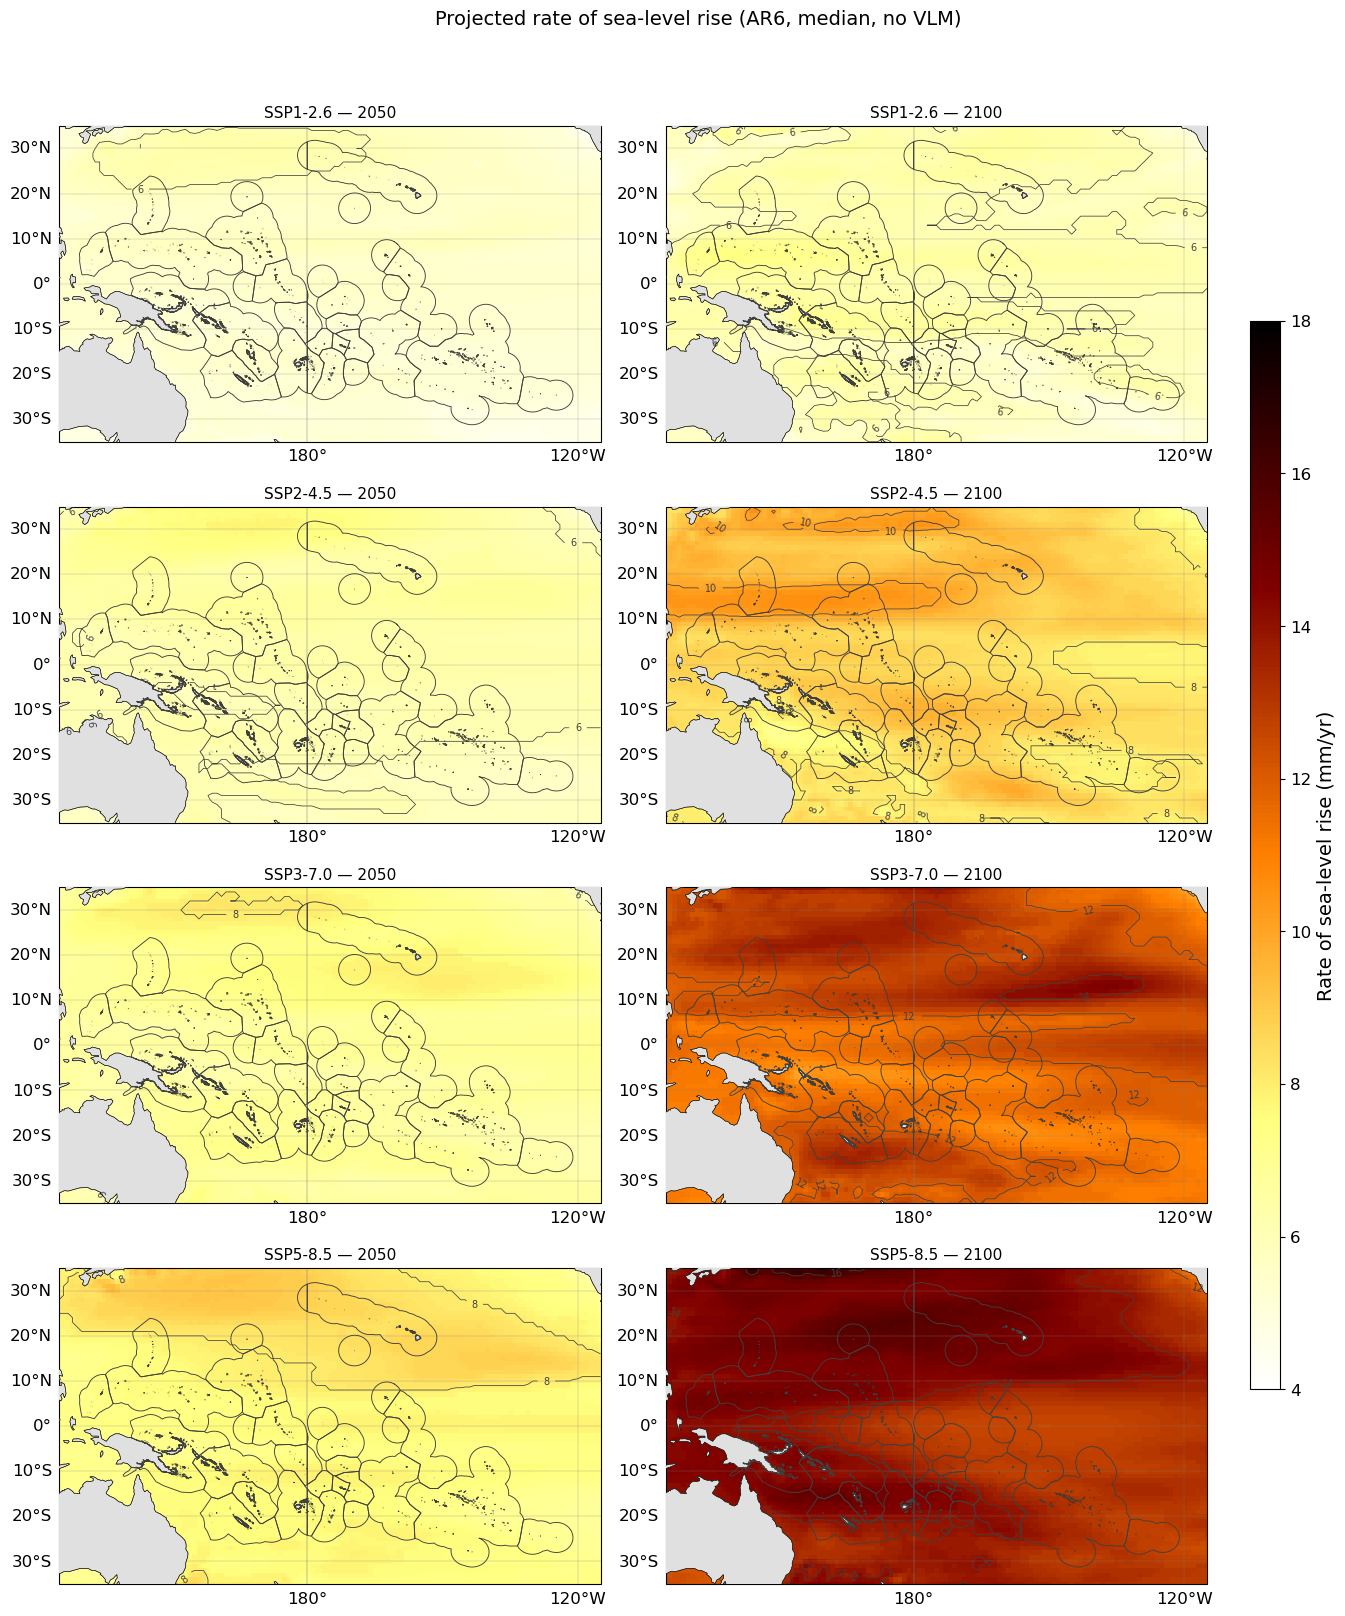

In [7]:
rate_vmin, rate_vmax, rate_levels = colour_limits(rate.sel(quantile=0.5, year=horizons), 2)
rate_panels = xr.concat(
    [fill_coast(rate).sel(scenario=s, quantile=0.5, year=y).drop_vars(['scenario', 'quantile', 'year'])
     for s in ssp_scenarios for y in horizons],
    dim=pd.Index([f'{ssp_label(s)} — {y}' for s in ssp_scenarios for y in horizons], name='panel'),
)
fig = plot_pacific_sst_panels(
    rate_panels, pacific, 'Projected rate of sea-level rise (AR6, median, no VLM)', dim='panel',
    cmap=seq_cmap, vmin=rate_vmin, vmax=rate_vmax, label='Rate of sea-level rise (mm/yr)', ncols=2,
    contour_levels=rate_levels, filename=fig_dir / f'PRJ_SL_rates_{product_tag}_pacific.png',
)
plt.show()

### Mean trend 2020–2100

Least-squares slope of the decadal median change between 2020 and 2100 (mm/yr): the average pace of rise over the century, directly comparable with the historical altimetry trend map (≈3.4 mm/yr over 1993–2025 for the same window).

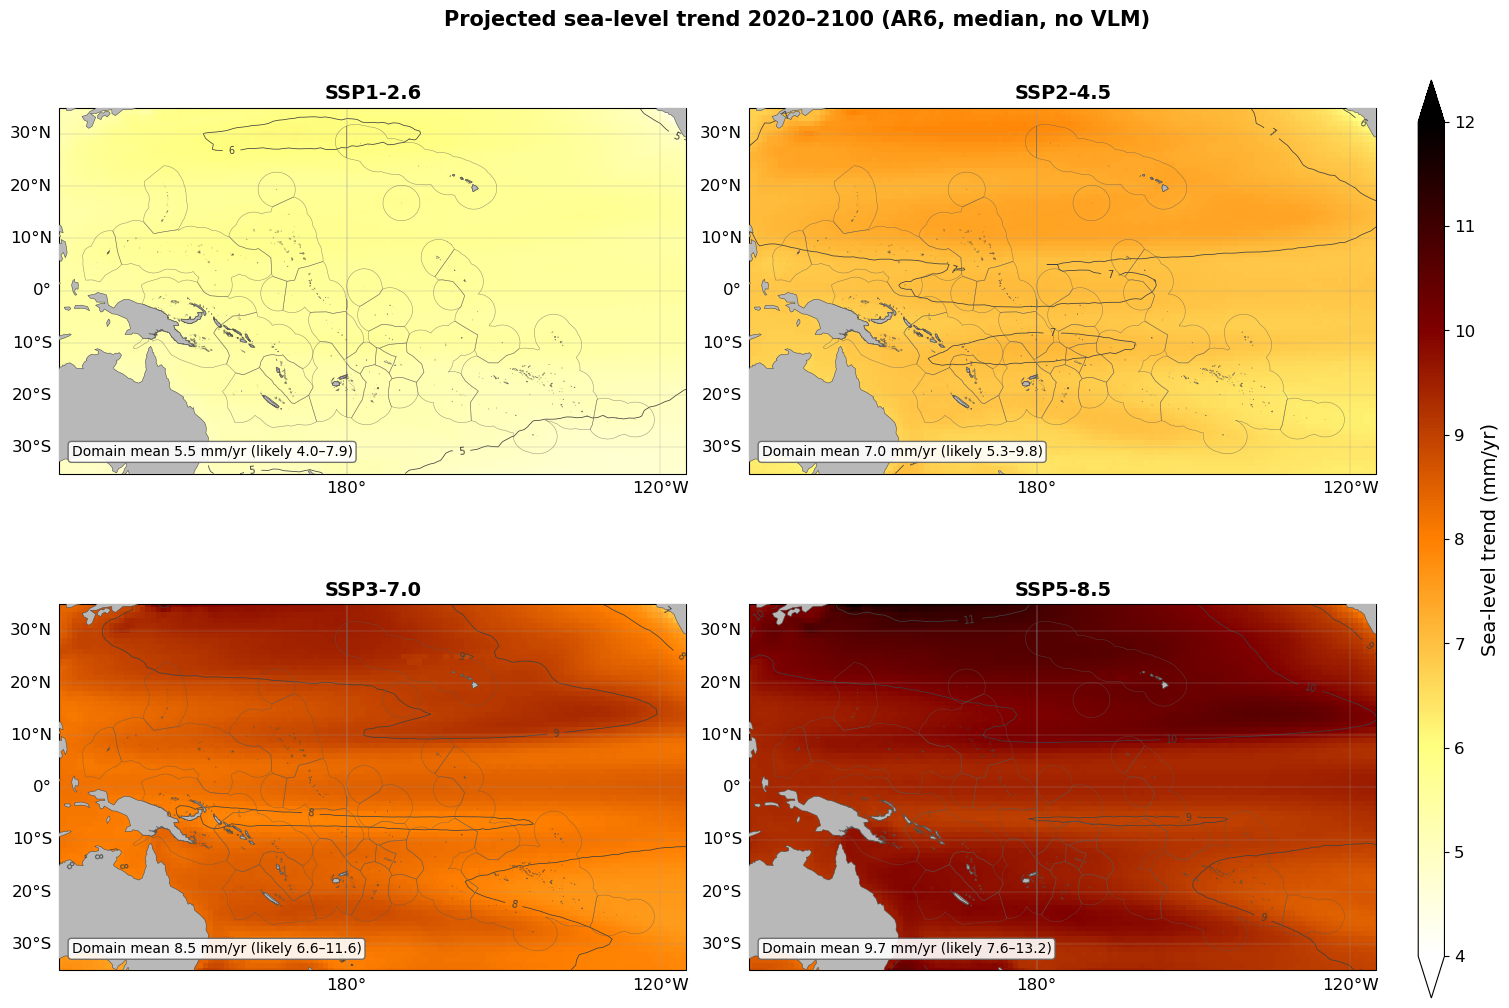

In [8]:
trend_mm = 10 * linear_trend(change.sel(quantile=0.5), *trend_period)   # cm/yr -> mm/yr
trend_label = f'{trend_period[0]}–{trend_period[1]}'
regional_trend = 10 * linear_trend(change_mean.sel(quantile=[0.17, 0.5, 0.83]), *trend_period)
fig = plot_projection_grid(
    {ssp_label(s): trend_mm.sel(scenario=s) for s in ssp_scenarios}, pacific,
    f'Projected sea-level trend {trend_label} (AR6, median, no VLM)', 'Sea-level trend (mm/yr)',
    cmap=seq_cmap, vmin=trend_vmin, vmax=trend_vmax, contour_levels=trend_levels,
    annotations={ssp_label(s): f"Domain mean {float(regional_trend.sel(scenario=s, quantile=0.5)):.1f} mm/yr "
                               f"(likely {float(regional_trend.sel(scenario=s, quantile=0.17)):.1f}–{float(regional_trend.sel(scenario=s, quantile=0.83)):.1f})"
                 for s in ssp_scenarios},
    filename=fig_dir / f'PRJ_SL_trend_{trend_period[0]}_{trend_period[1]}_{product_tag}_pacific.png',
)
plt.show()

## 6. Regional mean

Area-weighted mean over every ocean cell of the window, with the likely range (17th–83rd percentiles). The quantiles are averaged cell by cell, which approximates the uncertainty of the regional mean.

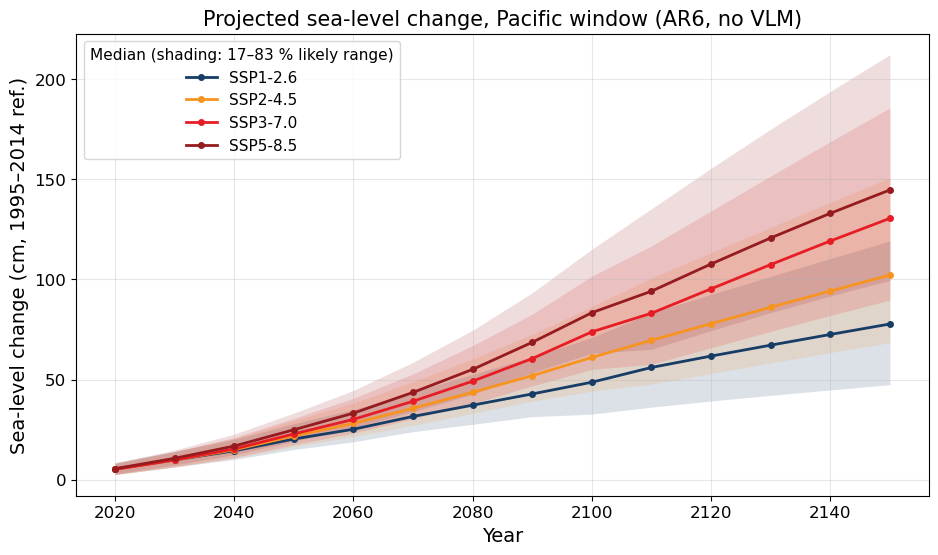

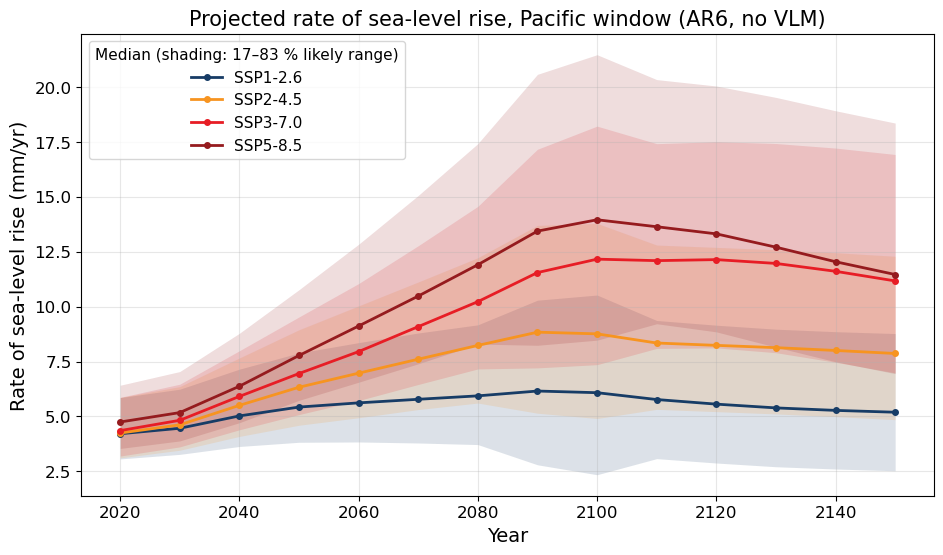

,Scenario,Year,change_cm_median,change_cm_likely_low,change_cm_likely_high,change_cm_very_likely_low,change_cm_very_likely_high,rate_mm_yr_median,rate_mm_yr_likely_low,rate_mm_yr_likely_high
0,SSP1-2.6,2050,20.4,15.1,28.0,12.0,35.0,5.4,3.8,7.9
1,SSP1-2.6,2100,48.7,32.8,71.0,23.8,90.7,6.1,2.3,10.5
2,SSP2-4.5,2050,21.9,16.6,29.6,13.5,36.4,6.3,4.6,8.9
3,SSP2-4.5,2100,61.1,44.3,86.3,35.2,108.6,8.8,4.9,13.8
4,SSP3-7.0,2050,22.9,17.6,30.7,14.4,37.9,7.0,5.1,9.5
5,SSP3-7.0,2100,73.8,55.1,101.7,45.2,127.0,12.2,7.4,18.2
6,SSP5-8.5,2050,25.0,19.3,33.3,15.9,40.5,7.8,5.7,10.8
7,SSP5-8.5,2100,83.4,63.2,115.1,52.3,143.6,14.0,8.5,21.5


In [9]:
fig, ax = plot_domain_mean_series(change_mean, 'Projected sea-level change, Pacific window (AR6, no VLM)',
                                  'Sea-level change (cm, 1995–2014 ref.)')
fig.savefig(fig_dir / f'PRJ_SL_regional_mean_change_{product_tag}_pacific.png', dpi=150, bbox_inches='tight')
plt.show()

rate_mean = domain_mean(rate)
fig, ax = plot_domain_mean_series(rate_mean, 'Projected rate of sea-level rise, Pacific window (AR6, no VLM)',
                                  'Rate of sea-level rise (mm/yr)')
ax.legend(title='Median (shading: 17–83 % likely range)', loc='upper left', fontsize=11, title_fontsize=11)
fig.savefig(fig_dir / f'PRJ_SL_regional_mean_rate_{product_tag}_pacific.png', dpi=150, bbox_inches='tight')
plt.show()

rows = []
for scenario in ssp_scenarios:
    for year in horizons:
        c, r = change_mean.sel(scenario=scenario, year=year), rate_mean.sel(scenario=scenario, year=year)
        rows.append({'Scenario': ssp_label(scenario), 'Year': year,
                     'change_cm_median': float(c.sel(quantile=0.5)), 'change_cm_likely_low': float(c.sel(quantile=0.17)),
                     'change_cm_likely_high': float(c.sel(quantile=0.83)), 'change_cm_very_likely_low': float(c.sel(quantile=0.05)),
                     'change_cm_very_likely_high': float(c.sel(quantile=0.95)), 'rate_mm_yr_median': float(r.sel(quantile=0.5)),
                     'rate_mm_yr_likely_low': float(r.sel(quantile=0.17)), 'rate_mm_yr_likely_high': float(r.sel(quantile=0.83))})
regional_table = pd.DataFrame(rows).round(1)
reg.save_table(regional_table, tab_dir, f'SL_regional_mean_{product_tag}', index=False)
regional_table

## 7. Pacific EEZs and ocean regions

Mean projected change (cm) in each Pacific EEZ and in the four ocean regions of the regional projection analysis, as median (likely range). The full table with every quantile, both horizons and the rates is saved to `outputs/tables/regional_pacific/`.

In [10]:
eez_countries = reg.load_eez(eez_file)
eez_change = region_table(sl, eez_countries, 'change', horizons)
eez_rate = region_table(sl, eez_countries, 'rate', horizons)
reg.save_table(eez_change, tab_dir, f'SL_eez_change_{product_tag}', index=False)
reg.save_table(eez_rate, tab_dir, f'SL_eez_rate_{product_tag}', index=False)
likely_range_table(eez_change, horizons[-1])[[ssp_label(s) for s in ssp_scenarios]]

Scenario,SSP1-2.6,SSP2-4.5,SSP3-7.0,SSP5-8.5
Region,,,,
American Samoa,48 (31–70),61 (44–87),72 (52–100),82 (61–114)
Cook Islands,47 (31–69),60 (44–85),70 (52–98),80 (60–112)
Fiji,48 (32–70),60 (42–86),74 (53–103),84 (63–116)
French Polynesia,46 (32–66),58 (42–82),69 (52–95),78 (59–108)
Hawaii,52 (36–75),66 (48–92),80 (60–110),91 (70–124)
Howland Island and Baker Island,49 (32–73),61 (45–86),73 (53–102),81 (58–114)
Jarvis Island,49 (32–73),60 (43–86),73 (54–102),80 (57–114)
Johnston Atoll,50 (35–73),65 (47–91),78 (58–107),88 (70–120)
Kiribati,49 (32–72),61 (45–86),72 (52–100),80 (58–114)


## 8. Summary metrics

In [11]:
metrics = {
    'source': sl.attrs['source'],
    'product': sl.attrs['product'],
    'vertical_land_motion': sl.attrs['vertical_land_motion'],
    'reference_period': '1995–2014',
    'extent': list(pacific_extent),
}
for scenario in ssp_scenarios:
    for year in horizons:
        c = change_mean.sel(scenario=scenario, year=year)
        metrics[f'{scenario}_{year}_change_cm_median'] = round(float(c.sel(quantile=0.5)), 1)
        metrics[f'{scenario}_{year}_change_cm_likely'] = [round(float(c.sel(quantile=q)), 1) for q in (0.17, 0.83)]
        metrics[f'{scenario}_{year}_rate_mm_yr_median'] = round(float(rate_mean.sel(scenario=scenario, year=year, quantile=0.5)), 1)
    metrics[f'{scenario}_trend_{trend_period[0]}_{trend_period[1]}_mm_yr_median'] = round(float(regional_trend.sel(scenario=scenario, quantile=0.5)), 2)
save_dict_json(metrics, tab_dir, f'PRJ_SL_summary_metrics_{product_tag}_pacific.json')
pd.Series(metrics).to_frame('value')

,value
source,"IPCC AR6 sea-level projections, Garner et al. ..."
product,"regional_novlm total, medium confidence"
vertical_land_motion,excluded
reference_period,1995–2014
extent,"[125, 245, -35, 35]"
ssp126_2050_change_cm_median,20.4
ssp126_2050_change_cm_likely,"[15.1, 28.0]"
ssp126_2050_rate_mm_yr_median,5.4
ssp126_2100_change_cm_median,48.7
ssp126_2100_change_cm_likely,"[32.8, 71.0]"


## Interpretation and reproducibility notes

- **Source:** IPCC AR6 WGI sea-level projections (Fox-Kemper et al., 2021), distributed by Garner et al. (2021), Zenodo [10.5281/zenodo.6382554](https://doi.org/10.5281/zenodo.6382554), `ar6-regional_novlm-confidence`, total, medium confidence.
- **No vertical land motion:** the projections are of absolute (geocentric) sea level, comparable with satellite altimetry. Relative sea-level change at a coast also depends on local subsidence or uplift (see the altimetry minus tide-gauge differences in the historical notebook); use `include_vlm = True` for relative projections.
- **Reference and horizons:** change is relative to the 1995–2014 mean (centred on 2005). Values for 2050 already include the ~2–3 cm of rise that occurred between 2005 and 2020.
- **Uncertainty:** maps show the median; the likely range (17–83 %) is given for the regional mean and the EEZ table. Medium confidence excludes ice-sheet processes with low confidence (e.g. marine ice-cliff instability), which could raise the upper tail substantially, especially after 2100.
- **Spatial scope:** the 1° grid resolves the basin-scale fingerprint (ocean dynamics and gravitational, rotational and deformational effects of land-ice loss) but not coastal processes. Cells whose centre falls on Natural Earth land are masked (maps extend the nearest ocean values up to two cells under the coastline only for display); the regional mean is an area-weighted average of all ocean cells in the window, not of the EEZs. EEZ and region means average each quantile spatially, which approximates the uncertainty of the area mean.
- **Rates and trends:** AR6 rates are decadal rates of change; the 2020–2100 trend is a least-squares slope through the decadal medians and smooths the acceleration.
- **Data volume:** the first run downloads ~110 MB per scenario (only the required members of the 8.7 GB archive) and creates a ~40 MB cache; later runs reuse both. Set `force_download = True` to refresh.